# The `EC` Mechanism: Coupled Follow-Up Chemical Reaction

## 1. Goal

Model an `EC` mechanism ($\text{Ox} + e^- \rightleftharpoons \text{Red}$, $\text{Red} \xrightarrow{k_c} \text{P}$) using `Mechanism`, `ElectrochemicalStep`, and `FirstOrderReaction`, and observe how increasing $k_c$ diminishes the reverse anodic peak.

## 2. Physical Setup

We define three species (`Ox`, `Red`, `P`) and couple a fast reversible-limit `ButlerVolmer` step ($k^0 = 10^{-2}\text{ m/s}$) with a homogeneous `FirstOrderReaction(red, P, k=k_c)`. The dimensionless kinetic parameter is $\lambda = k_c RT / (n F v)$.

In [1]:
# !pip install -q softpotato

import matplotlib.pyplot as plt

from softpotato.constants import FARADAY, GAS_CONSTANT, STANDARD_TEMPERATURE
from softpotato.geometry import PlanarGeometry
from softpotato.reactions import (
    ButlerVolmer,
    ElectrochemicalStep,
    FirstOrderReaction,
    Mechanism,
    Species,
)
from softpotato.techniques import CyclicVoltammetry, find_peaks, simulate

E0 = 0.0
D = 1.0e-9
c_bulk = 1.0
area = 7.07e-6
v = 0.1

ox = Species("Ox", diffusivity=D, bulk_concentration=c_bulk, standard_potential=E0, n_electrons=1)
red = Species("Red", diffusivity=D, bulk_concentration=0.0)
prod = Species("P", diffusivity=D, bulk_concentration=0.0)
kinetics = ButlerVolmer(k0=1.0e-2, alpha=0.5, E0=E0, n=1)
geometry = PlanarGeometry(area)
cv = CyclicVoltammetry(E_start=0.4, E_vertex1=-0.4, E_vertex2=0.4, scan_rate=v, dE=0.004)

kc_values = [0.0, 0.2, 1.0, 5.0]

## 3. Simulation

We construct a `Mechanism` for each $k_c$ and integrate with `solver="scipy_ivp"` (stiff `Radau` integrator with analytical Jacobian).

In [2]:
results = {}
for kc in kc_values:
    reactions = [FirstOrderReaction(red, prod, k=kc)] if kc > 0 else []
    mech = Mechanism(
        species=[ox, red, prod],
        electrochemical_steps=[ElectrochemicalStep(ox, red, kinetics)],
        reactions=reactions,
    )
    results[kc] = simulate(cv, mech, geometry=geometry, solver="scipy_ivp")

## 4. Diagnostics & Plots

We overlay the CVs and print $|I_{pa}/I_{pc}|$ and $E_{pc}$ as a function of $\lambda = k_c RT / (n F v)$.

k_c =  0.0 s^-1 (lambda =  0.00) | E_pc = -0.0287 V | |I_pa/I_pc| = 0.777
k_c =  0.2 s^-1 (lambda =  0.05) | E_pc = -0.0278 V | |I_pa/I_pc| = 0.309
k_c =  1.0 s^-1 (lambda =  0.26) | E_pc = -0.0244 V | |I_pa/I_pc| = 0.035
k_c =  5.0 s^-1 (lambda =  1.28) | E_pc = -0.0140 V | |I_pa/I_pc| = 0.000


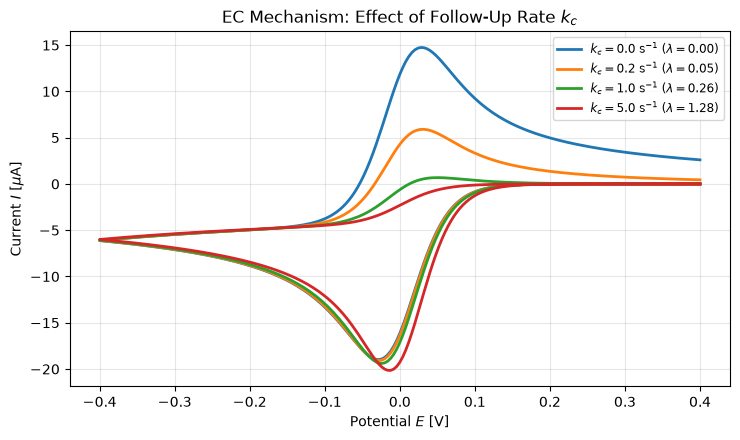

In [3]:
fig, ax = plt.subplots(figsize=(7.5, 4.5))
for kc, res in results.items():
    lam = kc * GAS_CONSTANT * STANDARD_TEMPERATURE / (FARADAY * v)
    peaks = find_peaks(res)
    ratio = peaks.peak_current_ratio if peaks.anodic_peak else 0.0
    print(f"k_c = {kc:4.1f} s^-1 (lambda = {lam:5.2f}) | E_pc = {peaks.cathodic_peak.E_peak:+.4f} V | |I_pa/I_pc| = {ratio:.3f}")
    ax.plot(res.potential, res.current * 1e6, lw=2, label=f"$k_c = {kc}$ s$^{{-1}}$ ($\\lambda = {lam:.2f}$)")

ax.set_xlabel("Potential $E$ [V]")
ax.set_ylabel(r"Current $I$ [$\mu$A]")
ax.set_title("EC Mechanism: Effect of Follow-Up Rate $k_c$")
ax.legend(fontsize=8.5)
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

## 5. Key Takeaways

- As $k_c$ (and $\lambda$) increases, $\text{Red}$ is chemically converted to electro-inactive $\text{P}$ before it can be re-oxidized on the reverse scan.
- The anodic return peak shrinks ($|I_{pa}/I_{pc}| \to 0$) and the forward cathodic peak shifts slightly positive.
- **Next**: Explore [EE Mechanism](cv_ee.ipynb) or [Catalytic EC' Mechanism](catalytic_ec.ipynb).